# SHAP Summary (Beeswarm)

**Family:** Multivariate & ML &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Multivariate & ML:* Explore many variables at once and explain or diagnose statistical and machine-learning models.

## Design purpose

One row per feature, one dot per prediction. A dot's horizontal position is how much that feature pushed that prediction up or down, and its color is the feature's value. The chart shows which features matter, in which direction, and for whom.

## When to use

- Explain a predictive model globally while keeping per-patient detail
- Show whether high values of a feature raise or lower the prediction
- Spot features whose effect is large for a few cases but small on average

## Avoid when

- Readers will take contributions as causal effects (they explain the model, not the world)
- Features are strongly correlated (attributions get split arbitrarily between them)
- You need a single explanation for one patient (use a waterfall/force plot)

## Alternatives

- Permutation importance (global ranking only)
- Partial dependence / ICE plot (shape of one feature's effect)

## Design tips

- Sort features by mean |contribution| and show the top 10–15
- Draw a zero line; the side of zero tells the direction
- For tree models use the shap package (TreeExplainer); this example avoids the dependency

## Example

A logistic regression predicting malignancy in the real Breast Cancer Wisconsin dataset (load_breast_cancer). For a linear model with independent features, the exact SHAP value of feature j is coef_j × (x_j − mean_j) on the log-odds scale. This example computes those values directly, without the shap package.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

### Data

In [2]:
bc = load_breast_cancer(as_frame=True)
X = pd.DataFrame(StandardScaler().fit_transform(bc.data), columns=bc.data.columns)
y = 1 - bc.target                      # 1 = malignant
model = LogisticRegression(C=0.1, max_iter=5000).fit(X, y)
# Exact SHAP values for a linear model (log-odds scale): coef * (x - mean)
shap = pd.DataFrame(model.coef_[0] * (X - X.mean()).values, columns=X.columns)
order = shap.abs().mean().sort_values(ascending=False).index[:10]
shap.abs().mean()[order].round(2)

worst texture           0.48
worst concave points    0.44
worst radius            0.42
worst perimeter         0.39
mean concave points     0.37
worst area              0.36
radius error            0.34
worst smoothness        0.34
worst concavity         0.33
mean texture            0.33
dtype: float64

### Plot

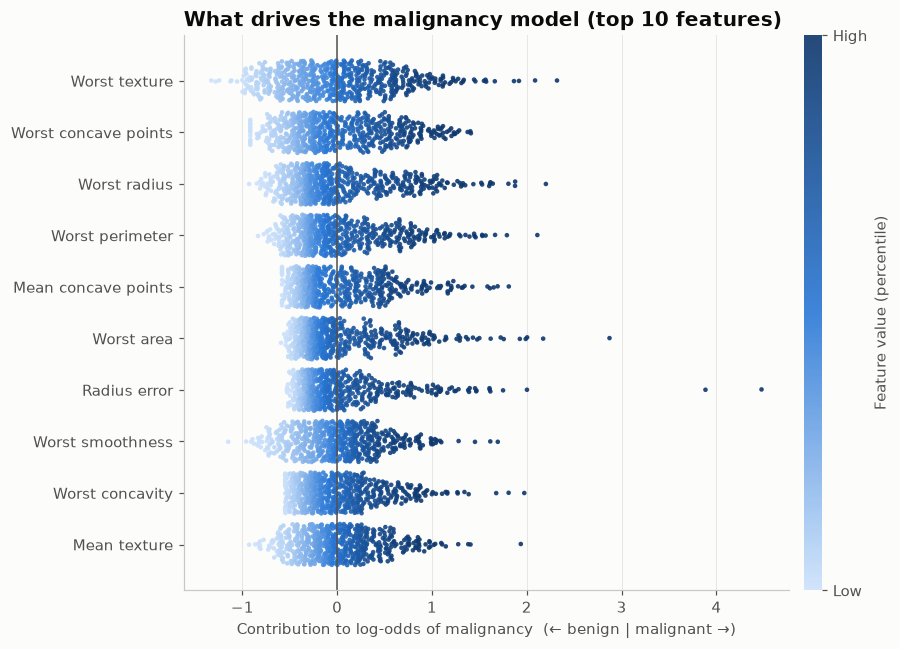

In [3]:
cmap = LinearSegmentedColormap.from_list("feat", ["#cde2fb", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(8.5, 6))
rng = np.random.default_rng(0)
for row, feat in enumerate(order[::-1]):
    v = shap[feat].values
    # beeswarm-style jitter: spread points vertically in proportion to local density
    bins = np.round(v / 0.08)
    offs = np.zeros_like(v)
    for b in np.unique(bins):
        idx = np.where(bins == b)[0]
        k = len(idx)
        offs[idx] = (np.arange(k) - (k - 1) / 2) * min(0.035, 0.8 / max(k, 1))
    offs += rng.uniform(-0.01, 0.01, len(v))
    fv = X[feat].rank(pct=True).values
    sc = ax.scatter(v, row + offs, c=fv, cmap=cmap, s=9, alpha=0.9, linewidth=0, vmin=0, vmax=1)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(range(len(order)), [f.capitalize() for f in order[::-1]])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribution to log-odds of malignancy  (← benign | malignant →)")
ax.set_title("What drives the malignancy model (top 10 features)")
cb = fig.colorbar(sc, ax=ax, pad=0.02, ticks=[0, 1], aspect=30)
cb.ax.set_yticklabels(["Low", "High"])
cb.set_label("Feature value (percentile)", color="#52514e")
cb.outline.set_visible(False)
fig.tight_layout()
plt.show()

## How to read it

"Worst texture" is the most influential feature. Light dots (low texture) sit left of zero and dark dots (high texture) sit right, so rougher texture pushes predictions towards malignant. A wide spread means the feature matters a lot for some tumours and little for others.

---
Standalone script: [`shap_summary.py`](shap_summary.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)